### 决策树 
树中每个内部节点表示一个特征上的判断，每个分支代表一个判断结果的输出
每个叶子节点代表一种分类结果

**信息熵 Entropy**
信息论中代表随机变量不确定度的度量
某特征的熵，p(xi)是标签列中某分类的占比
$$
H(x) = -\sum_{i=0}^{n} p(x_i) \log_2p(x_i)
$$

**条件熵**
在已知道特征X的取值后，标签Y剩余的不确定性
$$H(Y|X) = \sum_{x \in X} P(x) \cdot H(Y|X = x)$$
公式解析：
(1) 子节点自己的熵 H(Y|X = x)
(2) 把所有子节点的熵 按照该子节点样本数占总数的比例P(x)，特征列中某分类的占比，进行加权求和

**信息增益**
信息增益 = 信息熵-条件熵
$$
IG(D,A) = H(D) - H(D|A)
$$

## ID3决策树 (Iterative Dichotomiser 3)
优先考虑信息增益大的特征列，分类越多信息增益越大
**构建流程**
(1) 计算每个特征的信息增益
(2) 使用信息增益最大的特征将数据集拆分为子集
(3) 使用信息增益最大的特征作为决策树的一个节点
(4) 重复上述步骤

**缺点**
1.偏爱取值多的特征值
2.不能处理连续型特征
3.没有剪枝策略，只根据少数特征进行学习，容易过拟合



## C4.5树
ID3 决策树的缺点是偏爱“用户ID”这种取值极多的特征。
C4.5 的解决方案是：不直接看信息增益（Gain），而是看“信息增益”除以“分裂信息（Split Information）”的比值。
选择信息增益率大的特征作为分裂特征

**信息增益率（Gain Ratio）**
分支太多会导致虚高的信息增益，要除以一个惩罚项（分裂信息），分支越多越分散，惩罚项就越大
$$
GainRatio(D,A) = \frac{IG(D,A)}{SplitInfo(D,A)}
$$

**分裂信息（Split Information）**
衡量特征A本身的数量分支和均匀程度，也称特征熵
计算方式通信息熵，只是计算对象从标签换为了特征，p(xi)是特征列中某分类的占比
$$
H(x) = -\sum_{i=0}^{n} p(x_i) \log_2p(x_i)
$$


## CART决策树 (Classification and Regression Tree)

**Cart回归树**
使用平方误差最小化策略    预测输出一个连续值
用叶子节点多数类别作为预测类别

**Cart分类生成树**
使用基尼系数最小化策略    预测输出一个离散值
用叶子节点的均值作为预测输出

无论特征是离散还是连续，每一次分裂都只分两个子节点（例：红色、非红色）
即必须是二叉树

**基尼指数 Gini（D）**
从数据集D中随机抽取两个样本，其类别标记 不一致 的概率。Gini(D)值越小，数据集D的纯度越高
概率上的理解：样本容量无限大时，抽出一个样本不影响概率

节点D中有K个类别，pk是第k类样本的比例
$$
Gini(D) = 1 - \sum_{k = 1}^{K}p_k^2（1 - 每个类别概率的平方和）
$$

**基尼增益**
父节点的Gini减去子节点的Gini的加权和，选择增益最大的作为分裂特征
$$
Gini_Gain(D,A) = Gini(D) - \sum_{v=1}^2\frac{|D_v|}{|D|}Gini(D_v)
$$

**均方误差（MSE）**
计算所有样本的误差平方和的平均值。  即最小二乘 / 样本个数
损失函数：
$$
\text{MSE}(D) = \frac{1}{n} \sum_{i=1}^{n} (y_i - \hat{y}_i)^2
$$

**回归树增益**
父节点的MSE减去子节点的加权MSE
$$
Gain = MSE(D) - \sum_{v=1}^2\frac{|D_v|}{|D|}MSE(D_v)
$$

回归一般还是用线性回归，CART用来作分类

## 决策树剪枝
剪枝是一种防止决策树过拟合的一种正则化方法，将子树替换为叶子节点

**预剪枝（Pre-pruning）**
降低过拟合风险，显著减少决策树的训练、测试时间开销

但某个节点当前的收益很小，但下层收益可能会暴涨，预剪枝消除了这种可能
也有欠拟合的风险

**后剪枝（Post-pruning）**
比起预剪枝保留了更多的分支，泛化性能往往优于预剪枝
带来的欠拟合风险很小

但后剪枝是先生成后剪枝，训练时间开销比起未剪枝和预剪枝的决策树都要大得多

过拟合在决策树中表现为深度极深、叶子节点极多，只看当前增益的贪婪分裂算法，可能为了区分一个异常值，而开辟一个极深的路径
在数学模型上是把噪声（随机波动）当作了信号

欠拟合本质是模型太简单

✅ 测试集准确率 (Accuracy): 0.9778

📊 详细分类报告 (精确率/召回率/F1-score)：
                    precision    recall  f1-score   support

      山鸢尾 (Setosa)       1.00      1.00      1.00        15
 杂色鸢尾 (Versicolor)       1.00      0.93      0.97        15
维吉尼亚鸢尾 (Virginica)       0.94      1.00      0.97        15

          accuracy                           0.98        45
         macro avg       0.98      0.98      0.98        45
      weighted avg       0.98      0.98      0.98        45


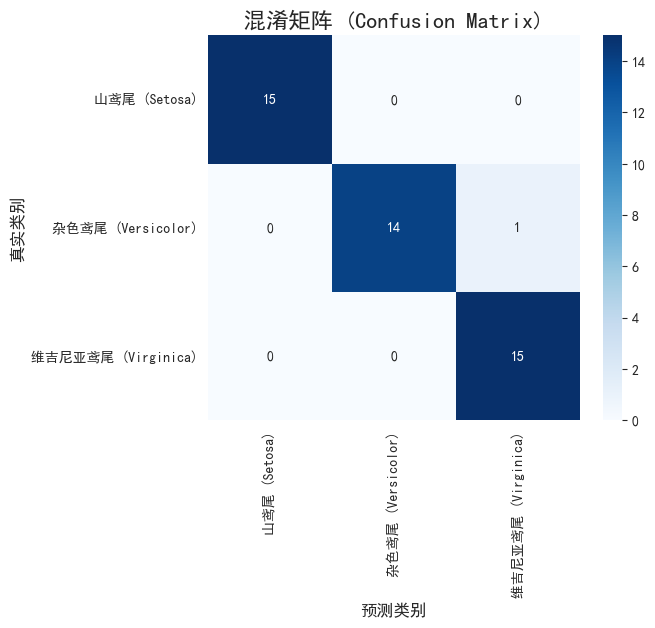

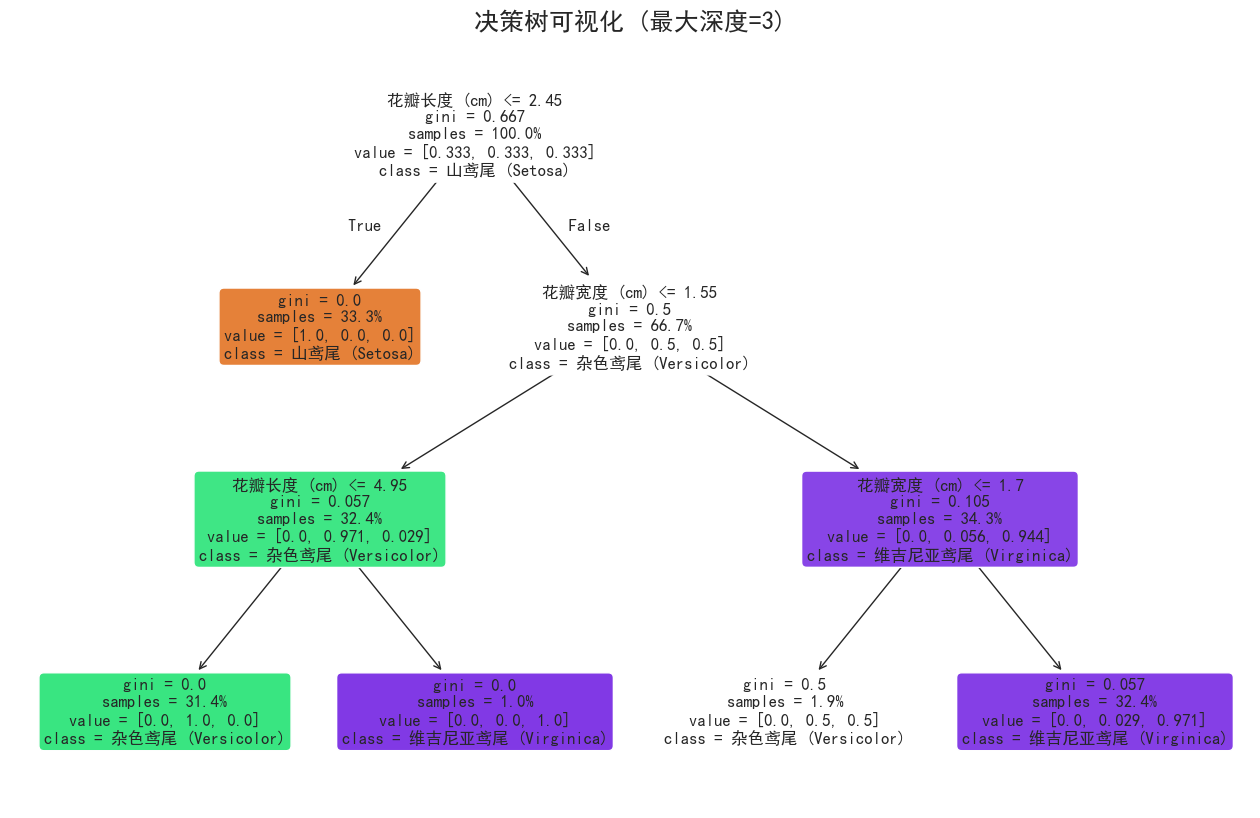


🔍 【特征重要性分析】
  花萼长度 (cm): 0.0000  
  花萼宽度 (cm): 0.0000  
  花瓣长度 (cm): 0.5509  ████████████████
  花瓣宽度 (cm): 0.4491  █████████████

🔮 【新样本预测结果】
  预测类别: 山鸢尾 (Setosa)
  各类别概率:
    - 山鸢尾 (Setosa): 100.00%
    - 杂色鸢尾 (Versicolor): 0.00%
    - 维吉尼亚鸢尾 (Virginica): 0.00%


In [3]:
# 1. 导入必要的库
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns

plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei', 'Arial Unicode MS']  
plt.rcParams['axes.unicode_minus'] = False  

# 2. 加载数据集
iris = load_iris()
X = iris.data          # 特征数据
y = iris.target        # 标签数据


feature_names_cn = ['花萼长度 (cm)', '花萼宽度 (cm)', '花瓣长度 (cm)', '花瓣宽度 (cm)']
target_names_cn = ['山鸢尾 (Setosa)', '杂色鸢尾 (Versicolor)', '维吉尼亚鸢尾 (Virginica)']

# 3. 划分训练集和测试集
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

# 4. 创建决策树模型（限制最大深度为3，便于展示）
model = DecisionTreeClassifier(
    max_depth=3,           # 限制深度，让树更清晰
    criterion='gini',      # 基尼系数
    random_state=42
)

# 5. 训练模型
model.fit(X_train, y_train)

# 6. 预测
y_pred = model.predict(X_test)

# 准确率
print(f"✅ 测试集准确率 (Accuracy): {accuracy_score(y_test, y_pred):.4f}")

# 分类报告
print("\n📊 详细分类报告 (精确率/召回率/F1-score)：")
print(classification_report(y_test, y_pred, target_names=target_names_cn))

# 混淆矩阵热力图
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=target_names_cn,   # X轴显示中文
            yticklabels=target_names_cn)   # Y轴显示中文
plt.title('混淆矩阵 (Confusion Matrix)', fontsize=16)
plt.xlabel('预测类别', fontsize=12)
plt.ylabel('真实类别', fontsize=12)
plt.show()

# 8. 可视化决策树结构
plt.figure(figsize=(16, 10))
plot_tree(
    model, 
    feature_names=feature_names_cn,   
    class_names=target_names_cn,      
    filled=True,                      
    rounded=True,                     # 圆角框
    fontsize=12,
    proportion=True                   # 显示样本占比
)
plt.title("决策树可视化 (最大深度=3)", fontsize=18)
plt.show()

# 9. 特征重要性
feature_importance = model.feature_importances_
print("\n🔍 【特征重要性分析】")
for name, importance in zip(feature_names_cn, feature_importance):
    # 用柱状图显示效果，这里用进度条样式直观展示
    bar = '█' * int(importance * 30)
    print(f"  {name}: {importance:.4f}  {bar}")

# 10. 新样本预测
new_sample = np.array([[5.1, 3.5, 1.4, 0.2]])
predicted_class = model.predict(new_sample)
predicted_proba = model.predict_proba(new_sample)

print("\n🔮 【新样本预测结果】")
print(f"  预测类别: {target_names_cn[predicted_class[0]]}")
print("  各类别概率:")
for name, prob in zip(target_names_cn, predicted_proba[0]):
    print(f"    - {name}: {prob:.2%}")